# Customer Segmentation using Machine Learning

## Project Objective

The objective of this project is to segment customers into different groups based on their purchasing behaviour using Machine Learning.

### Technologies Used

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-Learn
- KMeans Clustering
- StandardScaler
- Joblib

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

from sklearn.metrics import silhouette_score

import joblib
import json

import warnings
warnings.filterwarnings("ignore")

In [5]:
df = pd.read_excel("data.xlsx")

df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [6]:
print("Shape of Dataset :", df.shape)

print("\nColumns\n")
print(df.columns)

print("\nInformation\n")
df.info()

Shape of Dataset : (541909, 8)

Columns

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='str')

Information

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 40.0+ MB


In [7]:
df.describe(include="all")

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
count,541909.0,541909,540455,541909.000000,541909,541909.000000,406829.000000,541909
unique,25900.0,4070,4223,NaN,NaN,NaN,NaN,38
top,573585.0,85123A,WHITE HANGING HEART T-LIGHT HOLDER,NaN,NaN,NaN,NaN,United Kingdom
freq,1114.0,2313,2369,NaN,NaN,NaN,NaN,495478
mean,NaN,NaN,NaN,9.552250,2011-07-04 13:34:57.156386,4.611114,15287.690570,NaN
min,NaN,NaN,NaN,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000,NaN
25%,NaN,NaN,NaN,1.000000,2011-03-28 11:34:00,1.250000,13953.000000,NaN
50%,NaN,NaN,NaN,3.000000,2011-07-19 17:17:00,2.080000,15152.000000,NaN
75%,NaN,NaN,NaN,10.000000,2011-10-19 11:27:00,4.130000,16791.000000,NaN
max,NaN,NaN,NaN,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000,NaN


In [8]:
missing = pd.DataFrame({
    "Column": df.columns,
    "Missing Values": df.isnull().sum().values
})

missing

,Column,Missing Values
0,InvoiceNo,0
1,StockCode,0
2,Description,1454
3,Quantity,0
4,InvoiceDate,0
5,UnitPrice,0
6,CustomerID,135080
7,Country,0


In [9]:
print("Duplicate Rows :", df.duplicated().sum())

Duplicate Rows : 5268


In [10]:
df = df.drop_duplicates()

df = df.dropna(subset=["CustomerID"])

df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

df["CustomerID"] = df["CustomerID"].astype(int)

df["StockCode"] = df["StockCode"].astype(str)

df["InvoiceNo"] = df["InvoiceNo"].astype(str)

df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom


In [11]:
df["TotalPrice"] = df["Quantity"] * df["UnitPrice"]

df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


In [12]:
print(df.shape)

df.head()

(401604, 9)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


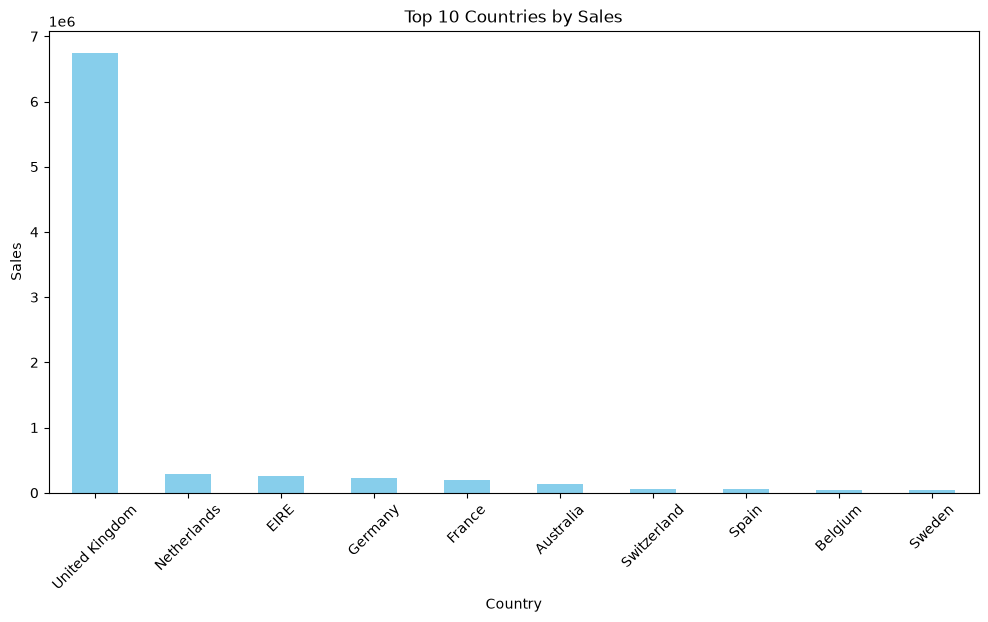

In [13]:
country_sales = df.groupby("Country")["TotalPrice"].sum().sort_values(ascending=False)

plt.figure(figsize=(12,6))

country_sales.head(10).plot(kind="bar", color="skyblue")

plt.title("Top 10 Countries by Sales")

plt.xlabel("Country")

plt.ylabel("Sales")

plt.xticks(rotation=45)

plt.show()

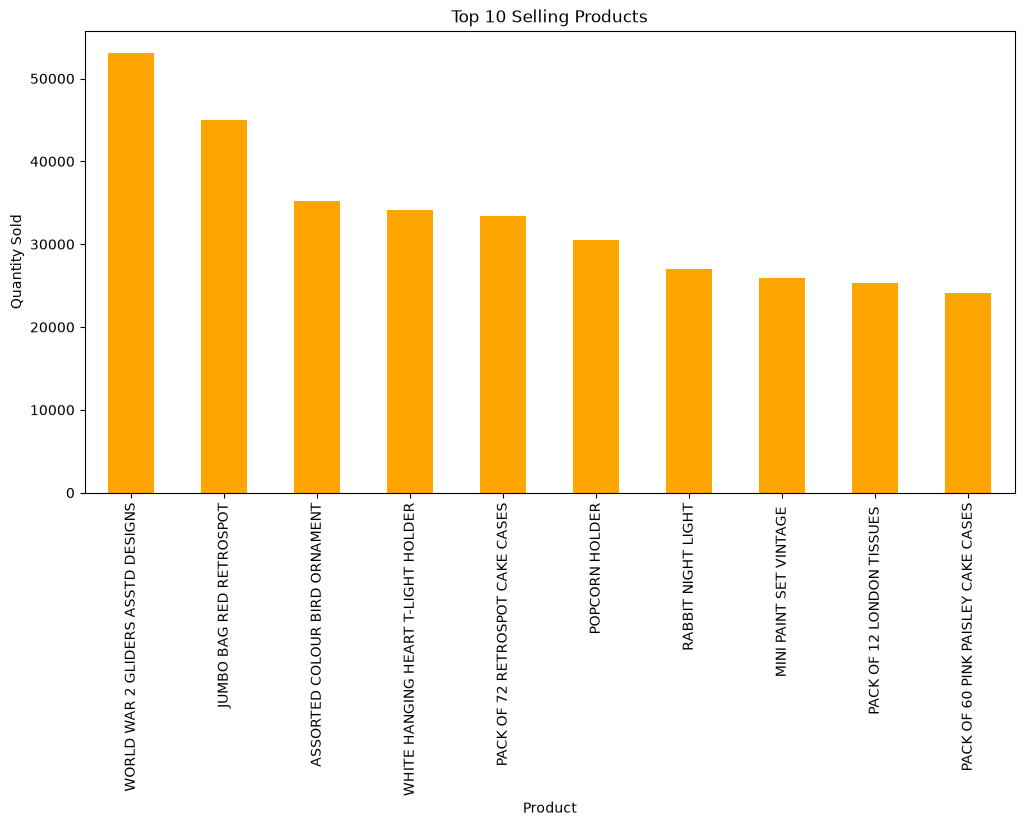

In [14]:
top_products = df.groupby("Description")["Quantity"].sum().sort_values(ascending=False)

plt.figure(figsize=(12,6))

top_products.head(10).plot(kind="bar", color="orange")

plt.title("Top 10 Selling Products")

plt.xlabel("Product")

plt.ylabel("Quantity Sold")

plt.xticks(rotation=90)

plt.show()

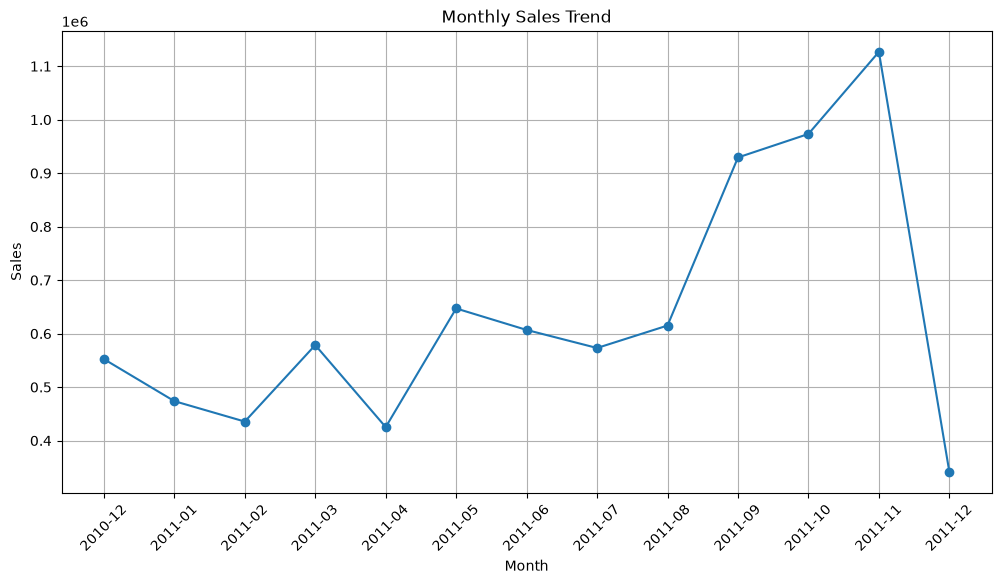

In [15]:

monthly_sales = df.groupby(df["InvoiceDate"].dt.to_period("M"))["TotalPrice"].sum()

monthly_sales.index = monthly_sales.index.astype(str)

plt.figure(figsize=(12,6))

plt.plot(monthly_sales.index, monthly_sales.values, marker="o")

plt.title("Monthly Sales Trend")

plt.xlabel("Month")

plt.ylabel("Sales")

plt.xticks(rotation=45)

plt.grid(True)

plt.show()

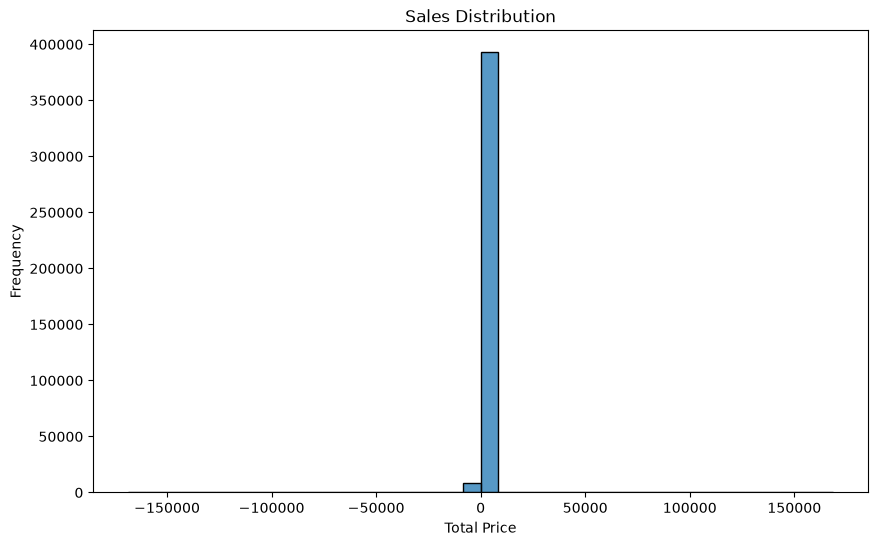

In [16]:
plt.figure(figsize=(10,6))

sns.histplot(df["TotalPrice"], bins=40)

plt.title("Sales Distribution")

plt.xlabel("Total Price")

plt.ylabel("Frequency")

plt.show()

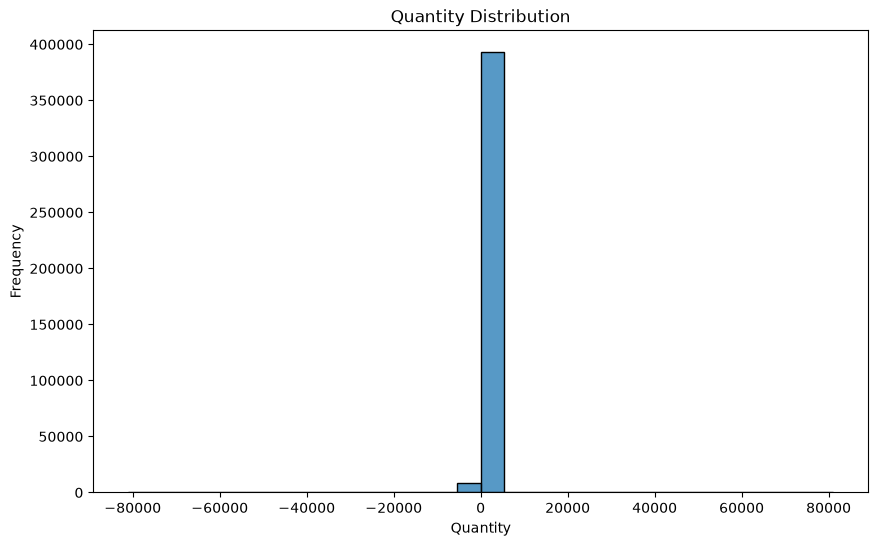

In [17]:
plt.figure(figsize=(10,6))

sns.histplot(df["Quantity"], bins=30)

plt.title("Quantity Distribution")

plt.xlabel("Quantity")

plt.ylabel("Frequency")

plt.show()

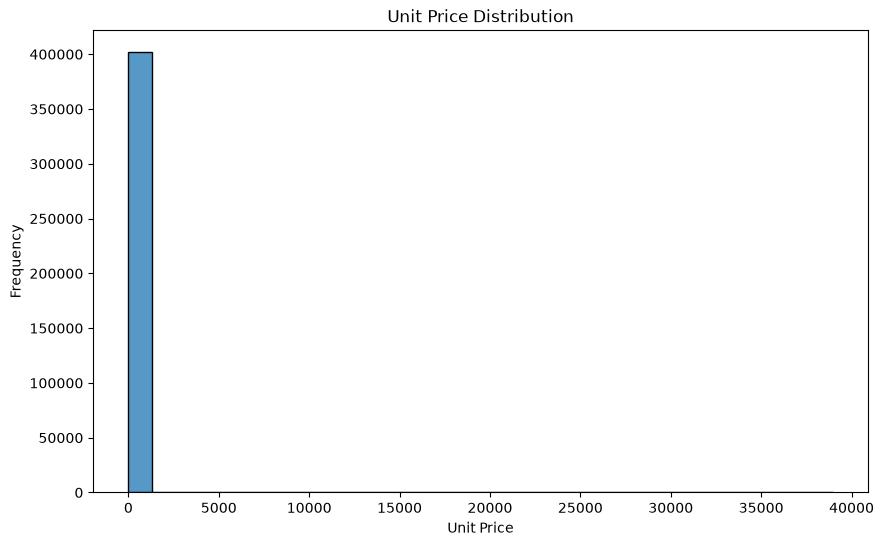

In [18]:
plt.figure(figsize=(10,6))

sns.histplot(df["UnitPrice"], bins=30)

plt.title("Unit Price Distribution")

plt.xlabel("Unit Price")

plt.ylabel("Frequency")

plt.show()

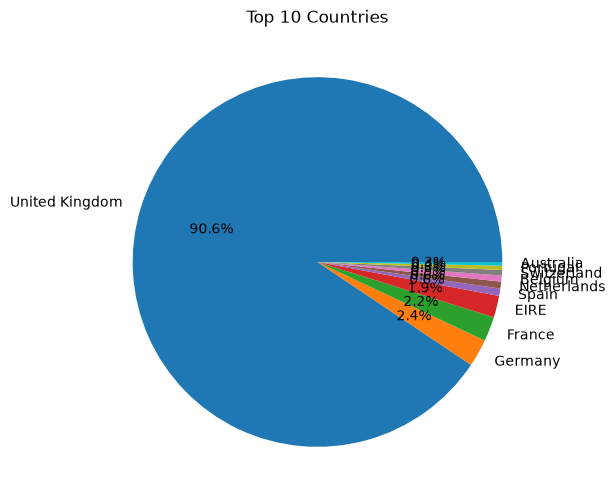

In [19]:
country_orders = df["Country"].value_counts().head(10)

plt.figure(figsize=(10,6))

country_orders.plot(kind="pie", autopct="%1.1f%%")

plt.title("Top 10 Countries")

plt.ylabel("")

plt.show()

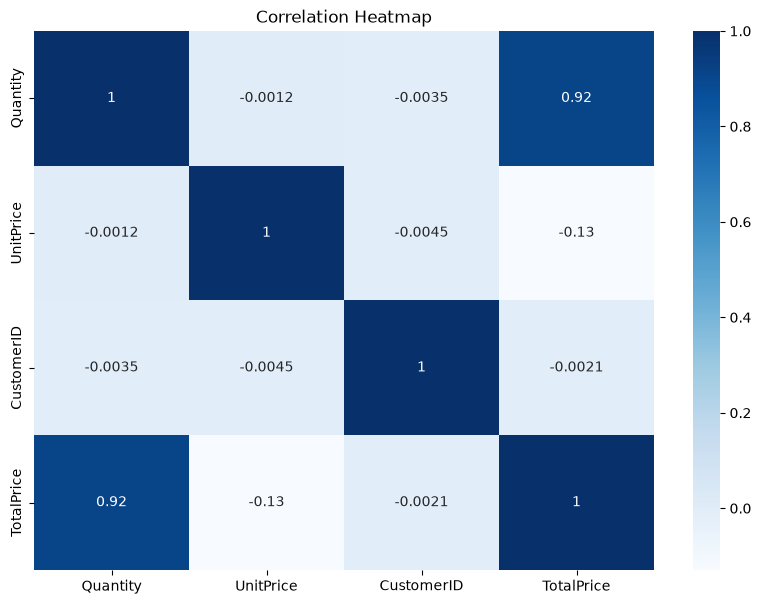

In [20]:
numeric_df = df.select_dtypes(include=["int64", "float64"])

plt.figure(figsize=(10,7))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="Blues"
)

plt.title("Correlation Heatmap")

plt.show()

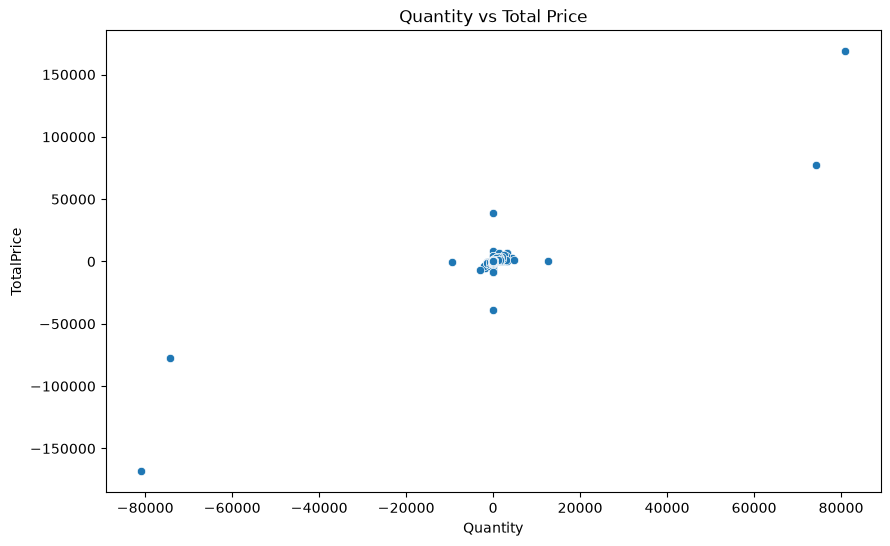

In [21]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=df,
    x="Quantity",
    y="TotalPrice"
)

plt.title("Quantity vs Total Price")

plt.show()

In [22]:
features = df[["Quantity", "UnitPrice", "TotalPrice"]]

features.head()

,Quantity,UnitPrice,TotalPrice
0,6,2.55,15.30
1,6,3.39,20.34
2,8,2.75,22.00
3,6,3.39,20.34
4,6,3.39,20.34


In [23]:
scaler = StandardScaler()

scaled_data = scaler.fit_transform(features)

scaled_data

array([[-0.02470515, -0.01324558, -0.0123472 ],
       [-0.02470515, -0.00120497, -0.00063585],
       [-0.01671419, -0.01037877,  0.00322146],
       ...,
       [-0.03269611,  0.00968891, -0.00932641],
       [-0.03269611,  0.00968891, -0.00932641],
       [-0.0366916 ,  0.02115615, -0.01339286]], shape=(401604, 3))

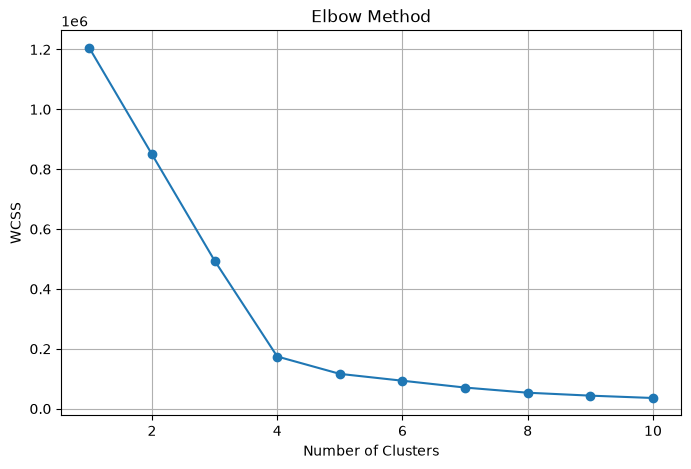

In [24]:
wcss = []

for i in range(1,11):

    kmeans = KMeans(
        n_clusters=i,
        random_state=42,
        n_init=10
    )

    kmeans.fit(scaled_data)

    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8,5))

plt.plot(range(1,11),wcss,marker="o")

plt.title("Elbow Method")

plt.xlabel("Number of Clusters")

plt.ylabel("WCSS")

plt.grid(True)

plt.show()

In [25]:
kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

df["Cluster"] = kmeans.fit_predict(scaled_data)

df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice,Cluster
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30,0
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,0
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00,0
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,0
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,0


In [26]:
df["Cluster"].value_counts()

Cluster
0    401569
4        30
3         2
1         2
2         1
Name: count, dtype: int64

In [27]:
cluster_summary = df.groupby("Cluster")[
    ["Quantity","UnitPrice","TotalPrice"]
].mean()

cluster_summary

,Quantity,UnitPrice,TotalPrice
Cluster,,,
0,12.184344,3.147902,20.745559
1,-77605.000000,1.560000,-122826.600000
2,-1.000000,38970.000000,-38970.000000
3,77605.000000,1.560000,122826.600000
4,-0.100000,3070.728333,-442.801667


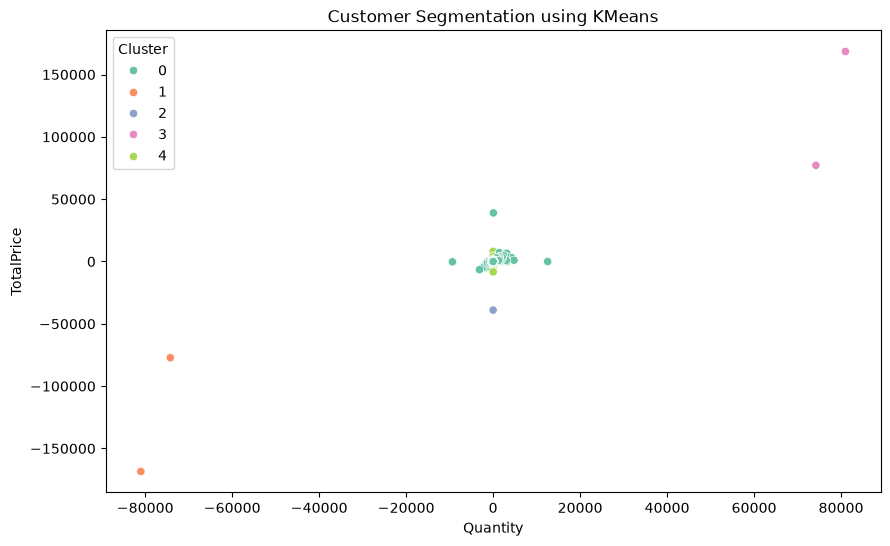

In [28]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=df,
    x="Quantity",
    y="TotalPrice",
    hue="Cluster",
    palette="Set2"
)

plt.title("Customer Segmentation using KMeans")

plt.show()

In [29]:
import joblib

joblib.dump(kmeans,"model.pkl")

joblib.dump(scaler,"scaler.pkl")

print("Model Saved Successfully")

Model Saved Successfully


In [30]:
cluster_info = {
    "0":"Premium Customer",
    "1":"Regular Customer",
    "2":"Loyal Customer",
    "3":"Budget Customer",
    "4":"At Risk Customer"
}

In [31]:
import json

with open("cluster_info.json","w") as file:
    json.dump(cluster_info,file,indent=4)

print("cluster_info.json Saved Successfully")

cluster_info.json Saved Successfully


In [32]:
df.head(20)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice,Cluster
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30,0
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,0
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00,0
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,0
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,0
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,2010-12-01 08:26:00,7.65,17850,United Kingdom,15.30,0
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,2010-12-01 08:26:00,4.25,17850,United Kingdom,25.50,0
7,536366,22633,HAND WARMER UNION JACK,6,2010-12-01 08:28:00,1.85,17850,United Kingdom,11.10,0
8,536366,22632,HAND WARMER RED POLKA DOT,6,2010-12-01 08:28:00,1.85,17850,United Kingdom,11.10,0
9,536367,84879,ASSORTED COLOUR BIRD ORNAMENT,32,2010-12-01 08:34:00,1.69,13047,United Kingdom,54.08,0


In [33]:
!pip install matplotlib


[notice] A new release of pip is available: 24.0 -> 26.1.2
[notice] To update, run: C:\Users\siddi\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [34]:
import sys
print(sys.executable)

C:\Users\siddi\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe
